In [ ]:
from google.colab import files
import zipfile
# Step 1: Upload zip file
uploaded = files.upload()

Saving eyesdiseaseds.zip to eyesdiseaseds.zip


In [ ]:
# Step 2: Unzip it
zip_path = "eyesdiseaseds.zip"  # Change to your uploaded filename
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
# Image settings
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

In [ ]:
# Define dataset path (pointing to the nested 'training data' directory)
DATASET_PATH = "dataset/training data"

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 1744 files belonging to 2 classes.
Using 1396 files for training.


In [ ]:
import os
# List the extracted directory structure to find the correct path to class folders
def print_directory_tree(startpath, max_depth=2):
    for root, dirs, files in os.walk(startpath):
        depth = root.replace(startpath, '').count(os.sep)
        if depth < max_depth:
            indent = ' ' * 4 * (depth)
            print(f'{indent}{os.path.basename(root)}/')
            subindent = ' ' * 4 * (depth + 1)
            for d in dirs[:5]:
                print(f'{subindent}{d}/')
            if len(dirs) > 5:
                print(f'{subindent}... and {len(dirs) - 5} more folders')
            break

print_directory_tree('dataset')

dataset/
    training data/


In [ ]:
# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 1744 files belonging to 2 classes.
Using 348 files for validation.


In [ ]:
# Get folder names in the same order used by TensorFlow
class_names = train_ds.class_names
print("Class names:", class_names)

# Improve loading speed
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

Class names: ['aug_disesed', 'healthy']


In [ ]:
# Create CNN model
# Using tf.keras.models and tf.keras.layers explicitly to avoid NameError
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),

    # Normalize pixel values
    tf.keras.layers.Rescaling(1./255),

    # First convolution block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

In [ ]:
# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,610 (18.42 MB)

 Trainable params: 4,828,610 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9842 - loss: 0.0446 - val_accuracy: 0.9971 - val_loss: 0.0178
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.9900 - loss: 0.0276 - val_accuracy: 0.9943 - val_loss: 0.0206
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.9928 - loss: 0.0207 - val_accuracy: 0.9914 - val_loss: 0.0195
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.9900 - loss: 0.0267 - val_accuracy: 0.9943 - val_loss: 0.0120
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.9914 - loss: 0.0210 - val_accuracy: 0.9943 - val_loss: 0.0099
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9914 - loss: 0.0179 - val_accuracy: 0.9971 - val_loss: 0.0071
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9921 - loss: 0.0161 - val_accuracy: 0.9971 - val_loss: 0.0067
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9936 - loss: 0.0147 - val_accuracy: 0.9971 - v

In [ ]:
# Save trained model
model.save("/content/eye_cnn_model.keras")

print("CNN model trained and saved successfully!")

CNN model trained and saved successfully!


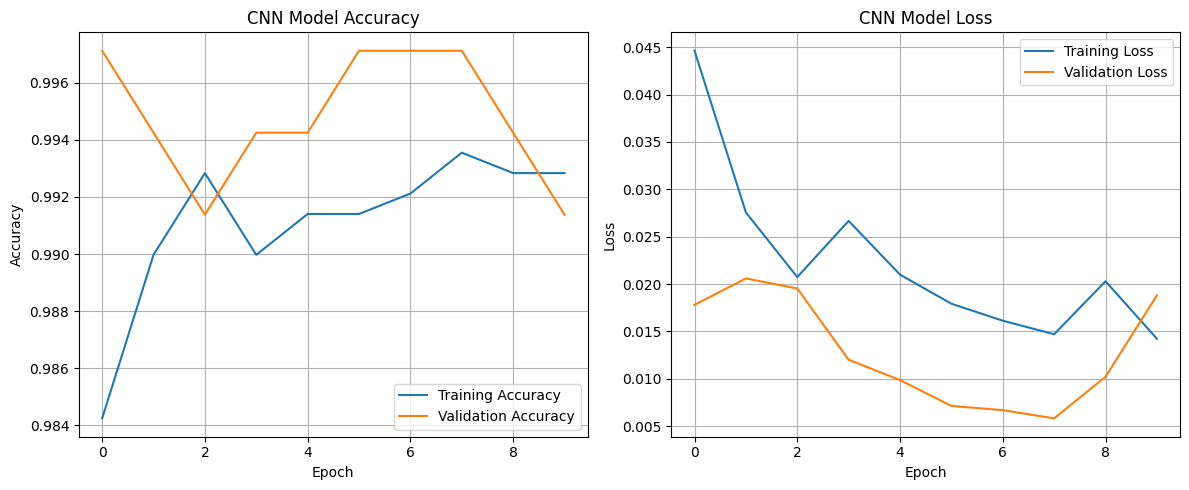

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import random

# 1. Class labels
class_names = ["disesed", "healthy"]

# 2. Extract a batch of images and labels from the validation dataset using an iterator
X_test, y_test = next(val_ds.as_numpy_iterator())

# 3. Pick 10 random indices from this batch
indices = random.sample(range(len(X_test)), min(10, len(X_test)))

[1.000000e+00 5.102924e-12]
[9.9999988e-01 1.6064732e-07]
[9.9999428e-01 5.7010857e-06]
[3.2915867e-08 1.0000000e+00]
[2.11809e-08 1.00000e+00]
[3.7807244e-12 1.0000000e+00]
[1.2590149e-11 1.0000000e+00]
[1.0000000e+00 2.7222202e-11]
[9.420984e-14 1.000000e+00]
[0.9942045  0.00579541]


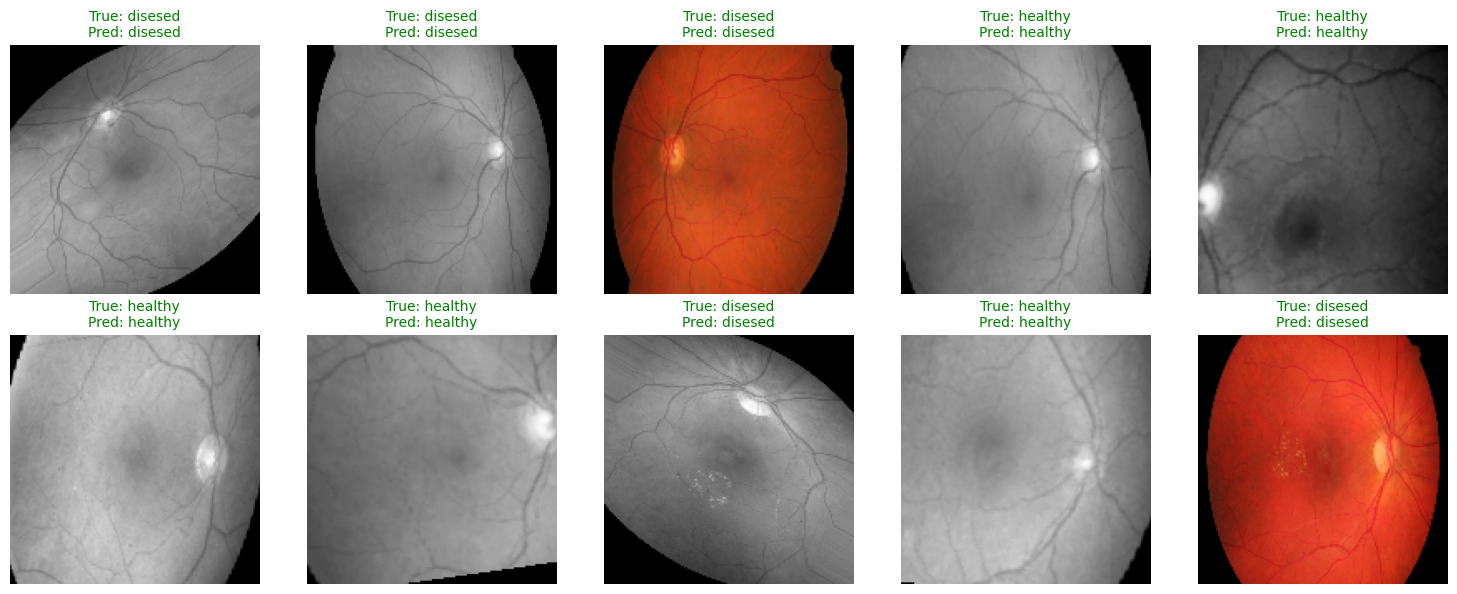

In [ ]:
plt.figure(figsize=(15, 6))

for i, idx in enumerate(indices):
    img = X_test[idx]
    true_label = y_test[idx]

    # Model expects batch dimension, so reshape to (1, 150, 150, 3)
    predictions = model.predict(img.reshape(1, 150, 150, 3), verbose=0)[0]
    pred_label = int(np.argmax(predictions))
    print(predictions)

    # Show image with actual and predicted labels
    plt.subplot(2, 5, i + 1)
    plt.imshow(img.astype("uint8"))
    plt.axis('off')

    color = "green" if pred_label == true_label else "red"
    plt.title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}", color=color, fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing import image

healthy_dir = 'dataset/training data/healthy'

files_in_dir = [f for f in os.listdir(healthy_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if len(files_in_dir) == 0:
    raise FileNotFoundError(f"No images found in {healthy_dir}")

test_image_path = os.path.join(healthy_dir, files_in_dir[0])
print("Loading and predicting image:", test_image_path)


test_image = image.load_img(test_image_path, target_size=IMG_SIZE)
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis=0)

result = model.predict(test_image, verbose=0)
predicted_class_idx = np.argmax(result[0])
predicted_class_name = class_names[predicted_class_idx]

print(f"Prediction probabilities: {result[0]}")
print(f"Predicted Class: {predicted_class_name} ({result[0][predicted_class_idx]*100:.2f}% confidence)")

Loading and predicting image: dataset/training data/healthy/_43_5112036.png
Prediction probabilities: [1.918059e-15 1.000000e+00]
Predicted Class: healthy (100.00% confidence)
